In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np


In [2]:
# Tugas 1: Modifikasi Model CNN CIFAR-10 (>80% Akurasi)
(X_train_cifar, y_train_cifar), (X_test_cifar, y_test_cifar) = datasets.cifar10.load_data()
X_train_cifar, X_test_cifar = X_train_cifar / 255.0, X_test_cifar / 255.0

tf.random.set_seed(42)

# Model CNN yang ditingkatkan (BatchNormalization + Dropout)
model_cifar_opt = models.Sequential([
    # Blok 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Blok 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Blok 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Classifier
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model_cifar_opt.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_cifar_opt.summary()


C:\Users\azure\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [3]:
# Pelatihan model modifikasi CIFAR-10
history_cifar = model_cifar_opt.fit(
    X_train_cifar, y_train_cifar,
    epochs=15,
    batch_size=128,
    validation_data=(X_test_cifar, y_test_cifar)
)


Epoch 1/15


  1/391 ━━━━━━━━━━━━━━━━━━━━ 39:14 6s/step - accuracy: 0.1094 - loss: 3.6134

  2/391 ━━━━━━━━━━━━━━━━━━━━ 1:19 205ms/step - accuracy: 0.1445 - loss: 3.4974

  3/391 ━━━━━━━━━━━━━━━━━━━━ 1:20 207ms/step - accuracy: 0.1484 - loss: 3.3991

  4/391 ━━━━━━━━━━━━━━━━━━━━ 1:19 204ms/step - accuracy: 0.1562 - loss: 3.2992

  5/391 ━━━━━━━━━━━━━━━━━━━━ 1:18 203ms/step - accuracy: 0.1562 - loss: 3.2511

... (5,885 outputs left out)

389/391 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.8597 - loss: 0.4092

390/391 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.8598 - loss: 0.4092

391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.8597 - loss: 0.4093

391/391 ━━━━━━━━━━━━━━━━━━━━ 83s 211ms/step - accuracy: 0.8597 - loss: 0.4093 - val_accuracy: 0.8029 - val_loss: 0.6217


Loss Data Uji CIFAR-10   : 0.6217
Akurasi Data Uji CIFAR-10: 80.29%


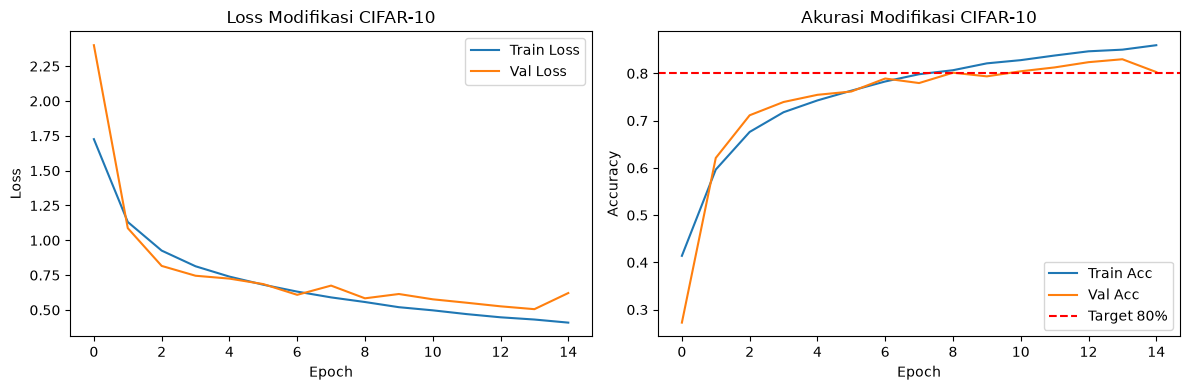

In [4]:
# Evaluasi performa model modifikasi CIFAR-10
cifar_loss, cifar_acc = model_cifar_opt.evaluate(X_test_cifar, y_test_cifar, verbose=0)
print(f'Loss Data Uji CIFAR-10   : {cifar_loss:.4f}')
print(f'Akurasi Data Uji CIFAR-10: {cifar_acc * 100:.2f}%')

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_cifar.history['loss'], label='Train Loss')
plt.plot(history_cifar.history['val_loss'], label='Val Loss')
plt.title('Loss Modifikasi CIFAR-10')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cifar.history['accuracy'], label='Train Acc')
plt.plot(history_cifar.history['val_accuracy'], label='Val Acc')
plt.axhline(0.80, color='r', linestyle='--', label='Target 80%')
plt.title('Akurasi Modifikasi CIFAR-10')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()


In [5]:
# Tugas 2: Model CNN Klasifikasi Citra MNIST
(X_train_mnist, y_train_mnist), (X_test_mnist, y_test_mnist) = datasets.mnist.load_data()
X_train_mnist = X_train_mnist.reshape(-1, 28, 28, 1) / 255.0
X_test_mnist = X_test_mnist.reshape(-1, 28, 28, 1) / 255.0

tf.random.set_seed(42)

# Bangun arsitektur CNN MNIST
model_mnist = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_mnist.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_mnist.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Pelatihan model CNN MNIST
history_mnist = model_mnist.fit(
    X_train_mnist, y_train_mnist,
    epochs=5,
    batch_size=64,
    validation_data=(X_test_mnist, y_test_mnist)
)


Epoch 1/5


  1/938 ━━━━━━━━━━━━━━━━━━━━ 10:19 661ms/step - accuracy: 0.0938 - loss: 2.3193

  7/938 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.2969 - loss: 2.1919     

 13/938 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.4099 - loss: 2.0123

 19/938 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.5058 - loss: 1.7960

 26/938 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.5607 - loss: 1.5667

... (745 outputs left out)

918/938 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9936 - loss: 0.0208

925/938 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9937 - loss: 0.0208

932/938 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9936 - loss: 0.0208

938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9936 - loss: 0.0208 - val_accuracy: 0.9879 - val_loss: 0.0391


Loss Data Uji MNIST   : 0.0391
Akurasi Data Uji MNIST: 98.79%


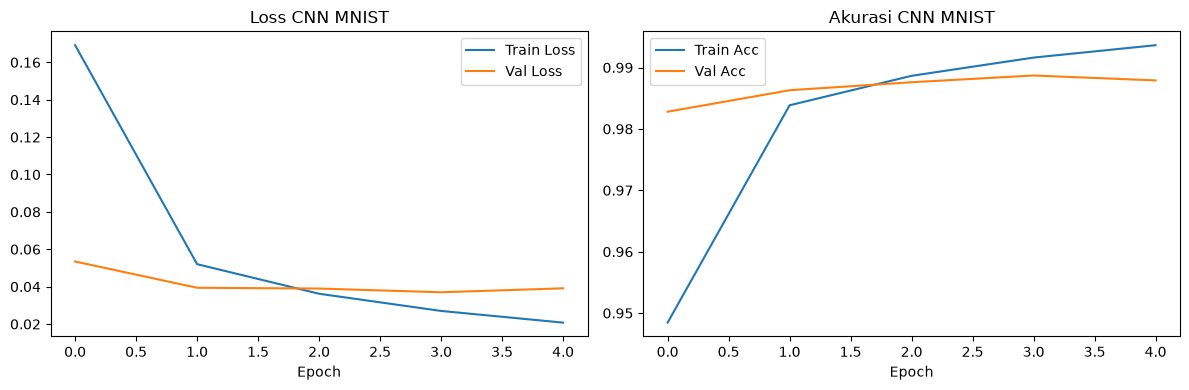

In [7]:
# Evaluasi performa model CNN MNIST
mnist_loss, mnist_acc = model_mnist.evaluate(X_test_mnist, y_test_mnist, verbose=0)
print(f'Loss Data Uji MNIST   : {mnist_loss:.4f}')
print(f'Akurasi Data Uji MNIST: {mnist_acc * 100:.2f}%')

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_mnist.history['loss'], label='Train Loss')
plt.plot(history_mnist.history['val_loss'], label='Val Loss')
plt.title('Loss CNN MNIST')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mnist.history['accuracy'], label='Train Acc')
plt.plot(history_mnist.history['val_accuracy'], label='Val Acc')
plt.title('Akurasi CNN MNIST')
plt.xlabel('Epoch')
plt.legend()
plt.tight_layout()
plt.show()
